# Classifier comparison and parameter play

We compare LinearSVC, K-neighbors, RBF SVC, Random Forest, and AdaBoost on a separate validation split. Then we vary Random Forest depth and minimum leaf size. The outer test set is kept untouched until one final evaluation. Identical ingredient vectors are grouped in both splits.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

raw = pd.read_csv(Path("../../../4-Classification/data/cuisines.csv"))
X = raw.drop(columns=["cuisine", "Unnamed: 0", "rice", "garlic", "ginger"]).astype(float)
y = raw.cuisine
# Group identical feature vectors, even when their labels disagree.
groups = pd.util.hash_pandas_object(X, index=False)
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
train_idx, test_idx = next(splitter.split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
assert set(groups.iloc[train_idx]).isdisjoint(set(groups.iloc[test_idx]))
assert X.shape[1] == 380 and X.isin([0, 1]).all().all()
print(f"Rows: {len(X)}; train: {len(X_train)}; test: {len(X_test)}; features: {X.shape[1]}")


Rows: 2448; train: 1960; test: 488; features: 380


,Train F1,Validation F1
Model,,
LinearSVC,0.8884,0.7464
KNeighbors,0.7239,0.6052
SVC,0.9225,0.7781
RandomForest,0.9877,0.7603
AdaBoost,0.6813,0.6752


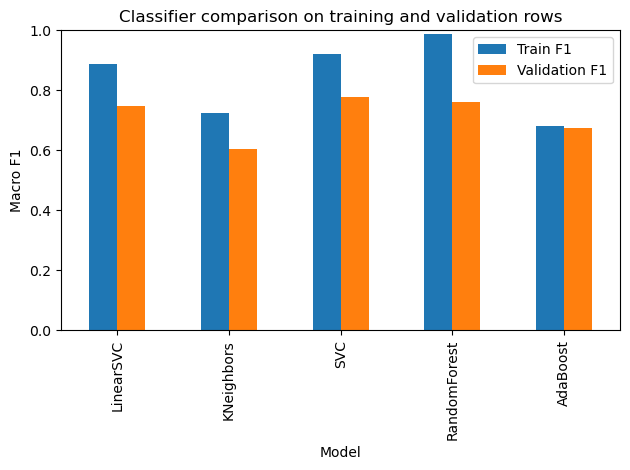

In [2]:
from sklearn.svm import LinearSVC, SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
inner = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=17)
fit_pos, valid_pos = next(inner.split(X_train, y_train, groups.iloc[train_idx]))
X_fit, X_valid = X_train.iloc[fit_pos], X_train.iloc[valid_pos]
y_fit, y_valid = y_train.iloc[fit_pos], y_train.iloc[valid_pos]
assert set(groups.iloc[train_idx].iloc[fit_pos]).isdisjoint(set(groups.iloc[train_idx].iloc[valid_pos]))
models = {
    "LinearSVC": LinearSVC(class_weight="balanced", max_iter=10000, random_state=42),
    "KNeighbors": KNeighborsClassifier(),
    "SVC": SVC(class_weight="balanced"),
    "RandomForest": RandomForestClassifier(n_estimators=100, class_weight="balanced", random_state=42),
    "AdaBoost": AdaBoostClassifier(n_estimators=100, random_state=42),
}
rows = []
for name, estimator in models.items():
    estimator.fit(X_fit, y_fit)
    rows.append({"Model": name, "Train F1": f1_score(y_fit, estimator.predict(X_fit), average="macro"), "Validation F1": f1_score(y_valid, estimator.predict(X_valid), average="macro")})
comparison = pd.DataFrame(rows).set_index("Model")
display(comparison.round(4))
comparison.plot.bar(title="Classifier comparison on training and validation rows")
plt.ylabel("Macro F1")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

## Assignment experiment

`max_depth=2` restricts interactions and can underfit. Unlimited depth can memorize rare ingredient combinations. Larger `min_samples_leaf` values smooth predictions and may reduce variance, but can erase useful minority patterns. We fix the random seed and number of trees so these two parameters are the changes under study. The selection metric is validation macro F1.

,Depth,Leaf,Train F1,Validation F1
0,2,1,0.6954,0.6790
1,2,5,0.6901,0.6768
2,2,20,0.6834,0.6608
3,8,1,0.8233,0.7251
4,8,5,0.7559,0.7265
5,8,20,0.7162,0.6817
6,unlimited,1,0.9877,0.7603
7,unlimited,5,0.8103,0.7494
8,unlimited,20,0.7197,0.7011


Best validation setting: depth=unlimited, leaf=1, F1=0.760
Worst validation setting: depth=2, leaf=20, F1=0.661


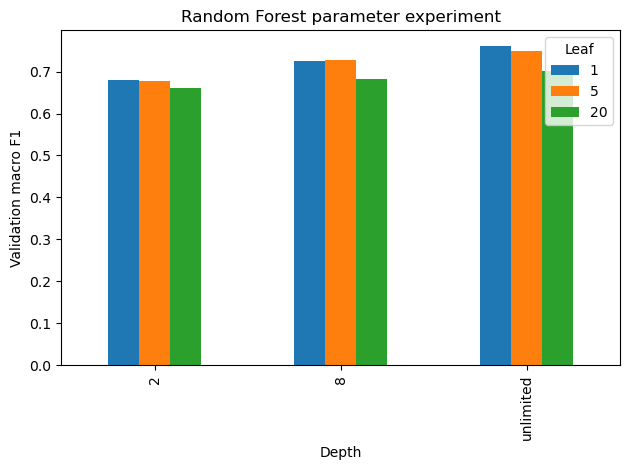

In [3]:
experiments = []
for depth in (2, 8, None):
    for leaf in (1, 5, 20):
        forest = RandomForestClassifier(n_estimators=100, max_depth=depth, min_samples_leaf=leaf, class_weight="balanced", random_state=42)
        forest.fit(X_fit, y_fit)
        experiments.append({"Depth": "unlimited" if depth is None else str(depth), "Leaf": leaf,
                            "Train F1": f1_score(y_fit, forest.predict(X_fit), average="macro"),
                            "Validation F1": f1_score(y_valid, forest.predict(X_valid), average="macro")})
experiment = pd.DataFrame(experiments)
display(experiment.round(4))
best = experiment.sort_values("Validation F1", ascending=False, kind="stable").iloc[0]
worst = experiment.sort_values("Validation F1", kind="stable").iloc[0]
print(f"Best validation setting: depth={best.Depth}, leaf={best.Leaf}, F1={best['Validation F1']:.3f}")
print(f"Worst validation setting: depth={worst.Depth}, leaf={worst.Leaf}, F1={worst['Validation F1']:.3f}")
experiment.pivot(index="Depth", columns="Leaf", values="Validation F1").plot.bar(title="Random Forest parameter experiment")
plt.ylabel("Validation macro F1")
plt.tight_layout()
plt.show()
assert np.isfinite(experiment[["Train F1", "Validation F1"]]).all().all()

Final test accuracy: 0.8074
Final test macro F1: 0.7679
              precision    recall  f1-score   support

     chinese       0.79      0.67      0.72        88
      indian       0.86      0.98      0.91       124
    japanese       0.70      0.51      0.59        61
      korean       0.80      0.91      0.85       152
        thai       0.82      0.71      0.76        63

    accuracy                           0.81       488
   macro avg       0.79      0.76      0.77       488
weighted avg       0.80      0.81      0.80       488



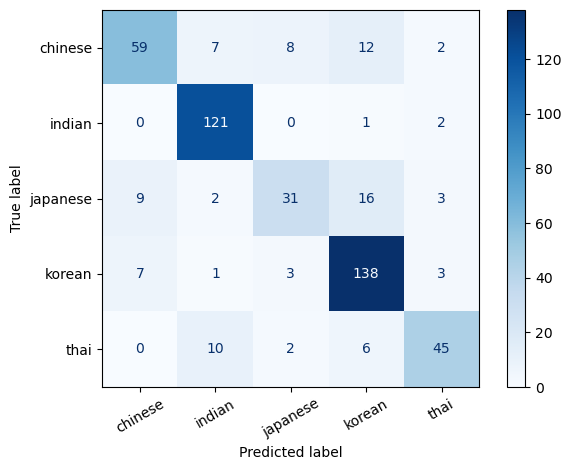

In [4]:
chosen_depth = None if best.Depth == "unlimited" else int(best.Depth)
final_model = RandomForestClassifier(n_estimators=100, max_depth=chosen_depth, min_samples_leaf=int(best.Leaf), class_weight="balanced", random_state=42)
final_model.fit(X_train, y_train)
final_prediction = final_model.predict(X_test)
print("Final test accuracy:", round(accuracy_score(y_test, final_prediction), 4))
print("Final test macro F1:", round(f1_score(y_test, final_prediction, average="macro"), 4))
print(classification_report(y_test, final_prediction, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, final_prediction, labels=final_model.classes_, cmap="Blues", xticks_rotation=30)
plt.tight_layout()
plt.show()

In [5]:
defaults = {"LinearSVC": LinearSVC(), "KNeighbors": KNeighborsClassifier(), "SVC": SVC(), "RandomForest": RandomForestClassifier(), "AdaBoost": AdaBoostClassifier()}
for name, estimator in defaults.items():
    print(name, estimator.get_params())

LinearSVC {'C': 1.0, 'class_weight': None, 'dual': 'auto', 'fit_intercept': True, 'intercept_scaling': 1, 'loss': 'squared_hinge', 'max_iter': 1000, 'multi_class': 'ovr', 'penalty': 'l2', 'random_state': None, 'tol': 0.0001, 'verbose': 0}
KNeighbors {'algorithm': 'auto', 'leaf_size': 30, 'metric': 'minkowski', 'metric_params': None, 'n_jobs': None, 'n_neighbors': 5, 'p': 2, 'weights': 'uniform'}
SVC {'C': 1.0, 'break_ties': False, 'cache_size': 200, 'class_weight': None, 'coef0': 0.0, 'decision_function_shape': 'ovr', 'degree': 3, 'gamma': 'scale', 'kernel': 'rbf', 'max_iter': -1, 'probability': False, 'random_state': None, 'shrinking': True, 'tol': 0.001, 'verbose': False}
RandomForest {'bootstrap': True, 'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': None, 'max_features': 'sqrt', 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n

## What the changes mean

Interpret the validation table rather than assuming greater depth always helps. A training score near one with a much lower validation score is evidence of overfitting. If depth 2 performs poorly on both sets, the model cannot represent enough ingredient interactions. Increasing leaf size averages more recipes per leaf but may underfit uncommon cuisines. The final test report estimates performance after selection; it must not be used to restart tuning.

For the other classifiers, smaller LinearSVC/SVC `C` increases regularization; SVC `gamma` changes the locality of the RBF kernel. Larger K-neighbor counts smooth the boundary but dilute minority neighborhoods, and distance weighting emphasizes nearer recipes. More forest trees usually stabilize the ensemble at extra compute cost. AdaBoost’s `learning_rate` controls each stage’s contribution and interacts with `n_estimators`. The printed defaults are from the actual installed version. A single validation split has sampling noise; grouped cross-validation would strengthen a future comparison.